# MNIST classification

Two convolutional stages learn local stroke features from handwritten digits. The run uses 55,000 training images, a seeded 5,000-image validation split, and all 10,000 official test images.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxwork as nj
from neuraljaxwork import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery/cnn'
print(f"NeuralJAXwork {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXwork 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

Input `[B,1,28,28]` in `[0,1]`; output `[B,10]` logits. Training dropout consumes an explicit runtime stream. Evaluation disables dropout.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.DigitCNN), language="python"))

class DigitCNN(nn.Module):
    """MNIST NCHW images to ten logits; width controls the smoke-test size."""

    def __init__(self, width=16, classes=10, *, rngs):
        super().__init__()
        self.conv1 = nn.Conv2d(1, width, 3, padding=1, rngs=rngs)
        self.conv2 = nn.Conv2d(width, width * 2, 3, padding=1, rngs=rngs)
        self.pool = nn.MaxPool2d(2)
        self.dropout = nn.Dropout(0.2)
        self.head = nn.Linear(width * 2 * 7 * 7, classes, rngs=rngs)

    def forward(self, x, *, rngs=None):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x))).reshape(x.shape[0], -1)
        return self.head(self.dropout(x, rngs=rngs))

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [3]:
display(Code(inspect.getsource(training.cnn_step), language="python"))

@jit
def cnn_step(model, optimizer, batch, rngs):
    x, y = batch

    def objective(candidate):
        logits = candidate(x, rngs=rngs)
        return F.cross_entropy(logits, y), (logits.argmax(-1) == y).sum()

    (loss, correct), grads = value_and_grad(objective, has_aux=True)(model)
    optimizer.step(grads)
    return {"loss": loss, "correct": correct, "count": y.size}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'cnn', '--download',
           '--output', str(RUN), *RECIPES['cnn']]
print(' '.join(command))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

/home/dev/NeuralJAXwork/.venv/bin/python -m examples.run cnn --download --output /home/dev/NeuralJAXwork/runs/gallery/cnn --epochs 10 --limit 55000 --eval-limit 10000 --batch-size 128


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,10,128,0,55000,5000,10000


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

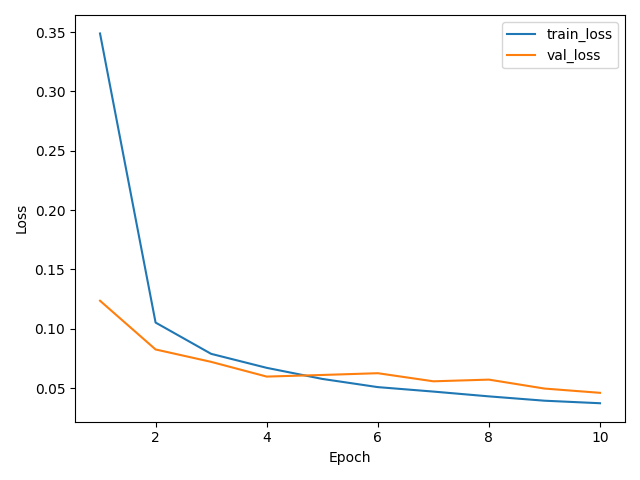

Selected epoch: 10


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

The confusion matrix reports all official test examples. The error gallery includes the first misclassified test images in dataset order, without selecting only attractive examples. The small CNN is a teaching baseline, not a state-of-the-art claim.

In [6]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

,Metric,Value
0,test_loss,0.030299
1,test_accuracy,0.989400
2,majority_baseline_accuracy,0.113500


Timed training loop (including validation/checkpoint work): 8.99 seconds


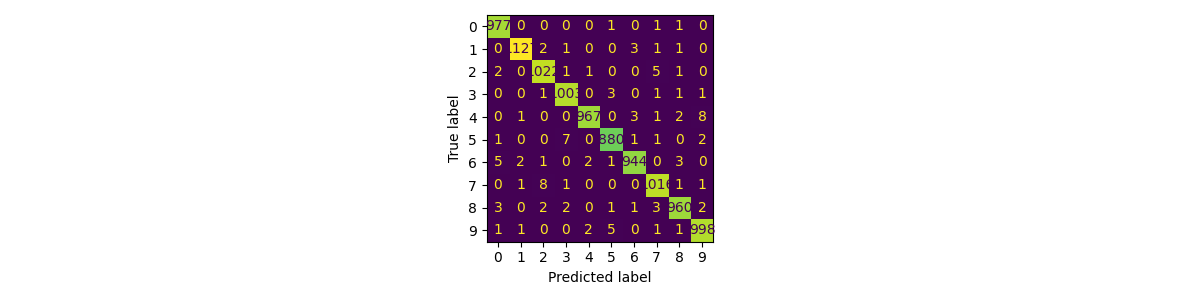

In [7]:
display(Image(filename=str(RUN / 'classification.png')))

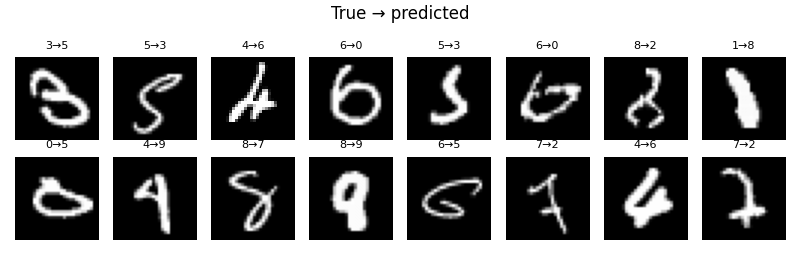

In [8]:
display(Image(filename=str(RUN / 'mistakes.png')))

## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.